In [48]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()
from pydantic import BaseModel,Field
from typing import Annotated,List,TypedDict
import operator
from langgraph.types import Send


In [49]:
class Section(BaseModel):
    id: int = Field(
        description="A unique identifier for the section."
    )
    title: str = Field(
        description="The title of an actual section that will appear in the final blog."
    )
    description: str = Field(
        description="A brief summary of the specific content that should be covered in this section."
    )

class OutlineSchema(BaseModel):
    outline:List[Section]

class SectionDraft(BaseModel):
    section_id:int
    title:str
    content:str

class BlogState(BaseModel):
    topic: str
    outline: List[Section] = []
    draft_sections: Annotated[List[SectionDraft], operator.add] = []
    final_blog: str = ""


In [50]:
model=ChatOpenAI(base_url="http://localhost:11434/v1",model='gemma')

In [61]:
graph=StateGraph(BlogState)

In [52]:
from datetime import datetime


def generate_outline(state:BlogState):
    llm=model.with_structured_output(OutlineSchema)
    prompt = f"""
    Create a detailed outline (3 points) for a blog about "{state.topic}".

    The outline must consist of the actual sections that will appear in the final blog.
    Each section should cover a distinct and meaningful aspect of the topic and follow a logical progression.

    For every section, provide:
    - A unique ID
    - A clear, descriptive section title
    - A concise description explaining what content should be covered in that section

    Do not include title suggestions, hooks, thesis statements, writing instructions, or meta-commentary.
    The output should represent the structure and content of the actual blog.
    """
    result=llm.invoke(prompt)
    return {
        'outline':result.outline
    }

def fanout_writers(state:BlogState):
    return [Send('writer',{"topic":state.topic,"section":sec}) for sec in state.outline]

def writer(state: dict):
    topic = state["topic"]
    section = state["section"]

    # print(section.id,'- entered writer node..',datetime.now().strftime("%H:%M:%S"))
    llm = model.with_structured_output(SectionDraft)

    prompt = f"""
    You are writing one section of a larger blog.

    Blog topic:
    {topic}

    Section title:
    {section.title}

    Section description:
    {section.description}

    Write the complete content for this section in 10 words.

    Requirements:
    - Stay focused on this section.
    - Provide useful, accurate, and substantive information.
    - Maintain a natural flow with the overall blog topic.
    - Do not write an introduction or conclusion for the entire blog.
    - Do not mention that you are an AI.
    - Do not refer to "this section" or the writing process.
    - Avoid unnecessary repetition.
    """

    result = llm.invoke(prompt)

    return {
        "draft_sections": [
            SectionDraft(
                section_id=section.id,
                title=section.title,
                content=result.content
            )
        ]
    }

def merge_sections(state: BlogState):
    sections = sorted(
        state.draft_sections,
        key=lambda x: x.section_id
    )

    content = "\n\n".join(
        f"## {section.title}\n\n{section.content}"
        for section in sections
    )

    return {
        "final_blog": content
    }

In [62]:
graph.add_node('generate_outline',generate_outline)
graph.add_node('writer',writer)
graph.add_node('merge_sections',merge_sections)

graph.add_conditional_edges('generate_outline',fanout_writers,['writer'])
graph.add_edge(START,'generate_outline')
graph.add_edge('writer','merge_sections')
graph.add_edge('merge_sections',END)



In [63]:
app=graph.compile()

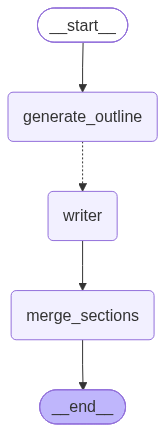

In [64]:
app

In [56]:
for event in app.stream({'topic':"Rise of AI"},stream_mode='tasks'):
    print(event,flush=True)

{'id': '6a2dc45b-7bbd-71fa-6b2e-04346bb598e3', 'name': 'generate_outline', 'input': BlogState(topic='Rise of AI', outline=[], draft_sections=[], final_blog=''), 'triggers': ('branch:to:generate_outline',)}
{'id': '6a2dc45b-7bbd-71fa-6b2e-04346bb598e3', 'name': 'generate_outline', 'error': None, 'result': {'outline': [Section(id=1, title='Defining Intelligence: The Foundations of Modern AI', description="This section will establish a foundational understanding of Artificial Intelligence by defining what AI is (narrow vs. general AI), tracing its historical milestones, and briefly explaining the core machine learning and deep learning concepts that power today's innovations."), Section(id=2, title='The Generative Leap: AI Across Industries', description='This section will explore the current tangible rise of AI, focusing on major applications across various sectors—including generative AI (text, image, code), personalized medicine, autonomous systems, and its immediate impact on producti

In [59]:
out

{'topic': 'Backpropagation in Deep learning',
 'outline': [Section(id=1, title='The Deep Learning Training Objective', description="Define the fundamental goal of training a neural network: minimizing the difference between the model's predictions and the true target values. Explain the role of the loss function in quantifying this error across the entire network."),
  Section(id=2, title='Understanding the Forward Pass', description='Detail the forward propagation process. Describe how input data flows through the layers, how weighted sums are calculated at each node, and how the network generates an output prediction for comparison against the target.'),
  Section(id=3, title='The Mechanics of Backpropagation: Applying the Chain Rule', description='Explain backpropagation as the algorithm used to calculate the gradient of the loss function with respect to every weight in the network. Focus on the critical role of the chain rule in efficiently propagating error signals backward from t